# Tugas Besar 2 IF3170 Inteligensi Artifisial

Prediksi pembatalan pemesanan penginapan.

## Group 31 - Kelompok Dadakan

- Farrel Limjaya (13524046)
- Raymond Jonathan Dwi Putra Julianto (13524059)
- Reynard Anderson Wijaya (13524111)
- Fauzan Mohamad Abdul Ghani (13524113)
- Hasna Nurul Alimah (11424061)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Bonus**](#12)


---

# Introduction <a name="1"></a>

---

Pemesanan yang dibatalkan dapat menyisakan kamar kosong. Prediksi sebelum kedatangan membantu penginapan merencanakan pengingat dan kebijakan pemesanan.

## Overview

Setiap baris mewakili satu pemesanan. Fitur mencakup jumlah tamu, lama menginap, pilihan kamar dan makanan, harga, serta riwayat pemesanan tamu.

## Aim

Menyiapkan data untuk memprediksi `is_canceled`: 1 berarti dibatalkan, 0 berarti tidak dibatalkan. Tahap berikutnya membandingkan lima model from scratch dengan scikit-learn.

## Metric

Kompetisi menggunakan Macro F1, yaitu rata-rata F1 untuk kelas tidak dibatalkan dan dibatalkan.

## Dataset

`train.csv` memiliki label `is_canceled`. `test.csv` tidak memiliki label dan digunakan untuk submission. `sample_submission.csv` menunjukkan kolom hasil yang diminta: `id` dan `is_canceled`.

| Kolom | Arti |
|---|---|
| `id` | Identitas unik pemesanan; disimpan sebagai teks. |
| `num_adults`, `num_children` | Jumlah tamu dewasa dan anak. |
| `weekend_nights`, `weekday_nights` | Jumlah malam akhir pekan dan hari kerja. |
| `meal_package` | Paket makanan. |
| `needs_parking` | Kebutuhan parkir: 0 atau 1. |
| `room_category` | Jenis kamar; huruf A sampai G tidak menunjukkan urutan kualitas. |
| `days_before_arrival` | Jarak hari dari pemesanan ke kedatangan. |
| `arrival_year`, `arrival_month`, `arrival_day` | Tanggal kedatangan. |
| `booking_channel` | Saluran pemesanan. |
| `is_returning_guest` | Pernah menginap sebelumnya: 0 atau 1. |
| `prior_cancellations`, `prior_completed_bookings` | Jumlah pemesanan sebelumnya yang dibatalkan dan tidak dibatalkan. |
| `nightly_rate_idr` | Harga rata-rata per kamar per malam; nol biasanya berarti gratis. |
| `special_requests` | Jumlah permintaan khusus. |
| `is_canceled` | Target pembatalan: 0 atau 1. |

## Approach

Alur pengerjaan mencakup pemeriksaan data, pembagian stratifikasi, preprocessing, pelatihan dan validasi model, perbandingan dengan scikit-learn, serta pembuatan submission. Statistik preprocessing dipelajari dari bagian training.


---

# Initialization <a name="2"></a>

---

Notebook menggunakan Python dengan NumPy, pandas, SciPy, scikit-learn, Matplotlib, dan IPython.


## Environment Setup

Sel berikut mencantumkan perintah instalasi pustaka pendukung apabila belum tersedia pada lingkungan Python.


In [1]:
# %pip install numpy pandas "scikit-learn>=1.2" matplotlib

## Import Libraries

Sel berikut mengimpor pustaka untuk pengolahan data, visualisasi, pembagian data, dan evaluasi model.


In [2]:
import os
from pathlib import Path
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

## Settings

Sel berikut menentukan lokasi data, seed, konfigurasi DTL, serta mengimpor modul proyek dan model pembanding.


In [3]:
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "train.csv").exists() and (p / "src").exists()
)
DATA_DIR = root / "data"
SEED = 42
sys.path.insert(0, str(root / "src" / "code"))

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

from preprocessing.common import impute, encode, scale
from preprocessing.lr_preprocessing import LRFeaturePreprocessor
from preprocessing.knn_svm_preprocessing import KNNSVMPreprocessor
from preprocessing.nb_preprocessing import NaiveBayesPreprocessor
from analysis.exploration import (
    overview, plot_distributions, check_data, heatmap,
    missing_values, duplicates, outliers, validate_values,
)
from models.decision_tree import DecisionTreeID3
from models.pruning import prune_cost_complexity, prune_macro_f1, prune_reduced_error
from models.logistic_regression import LogisticRegression
from models.svm import WorkingSetSVM
from models.knn import KNNFromScratch
from models.naive_bayes import NaiveBayes
from workflows.workflow import (
    train_model, evaluate_model, compare_models,
    calibrate_threshold, save_model, load_model, submit_model,
)
from workflows.dtl_workflow import train_dtl

KNN_PREP_CONFIG = dict(
    exponent=0.6, min_score=0.002, estimator="knn", n_neighbors=5,
    categorical_mi="group", random_state=SEED,
)
KNN_CONFIG = dict(
    k=41, metric="manhattan", weights="distance",
    weight_power=2.5, weight_eps=0.3,
    local_scale_k=15, local_scale_alpha=0.5, local_scale_eps=0.1,
    threshold=0.48,
)
DTL_CONFIG = dict(max_depth=None, min_samples_split=10, ccp_alpha=0.00035, calibrate=True, seed=SEED)

## Seed Everything

Pengaturan seed mendukung pengulangan proses yang melibatkan pengacakan.


In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(SEED)

## Load Dataset

Sel berikut membaca data training, test, dan contoh submission; mempertahankan `id` sebagai teks; serta memeriksa kesesuaian kolom dan urutan ID.


In [5]:
train_df = pd.read_csv(DATA_DIR / "train.csv", dtype={"id": str})
test_df = pd.read_csv(DATA_DIR / "test.csv", dtype={"id": str})
submission_example = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"id": str})

assert "is_canceled" in train_df and "is_canceled" not in test_df
assert train_df.drop(columns="is_canceled").columns.equals(test_df.columns)
assert submission_example["id"].equals(test_df["id"])
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
display(train_df.head())

Train: (27373, 19) | Test: (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


**Hasil:** Data training memiliki 27.373 baris dan 19 kolom, sedangkan data test memiliki 6.844 baris dan 18 kolom. Kolom target hanya tersedia pada data training.


---

# Data Understanding (Optional) <a name="3"></a>

---

Pemeriksaan awal mencakup struktur, distribusi, dan kualitas data. Statistik yang digunakan untuk preprocessing dihitung setelah data training dan validasi dipisahkan.


## Describe Data

Ringkasan berikut memperlihatkan tipe data, jumlah nilai unik, nilai kosong, dan statistik deskriptif pada `train.csv`.


In [6]:
display(overview(train_df))
display(train_df.describe().round(2))

,tipe,nilai_unik,kosong_train,persen_kosong_train
id,str,27373,0,0.00
num_adults,float64,5,809,2.96
num_children,float64,6,3035,11.09
weekend_nights,int64,8,0,0.00
weekday_nights,int64,18,0,0.00
meal_package,str,4,1760,6.43
needs_parking,float64,2,1082,3.95
room_category,str,7,1002,3.66
days_before_arrival,float64,407,1123,4.10
arrival_year,int64,2,0,0.00


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.00,24338.00,27373.00,27373.00,26291.00,26250.00,27373.00,27373.00,27373.00,27373.00,27373.00,27373.00,25335.00,24873.00,27373.00
mean,1.85,0.12,0.81,2.21,0.03,85.38,2023.82,7.40,15.54,0.03,0.02,0.14,1716979.55,0.67,0.33
std,0.52,0.43,0.88,1.42,0.17,85.97,0.38,3.07,8.77,0.16,0.36,1.69,587936.77,0.80,0.47
min,0.00,0.00,0.00,0.00,0.00,0.00,2023.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,1.00,0.00,17.00,2024.00,5.00,8.00,0.00,0.00,0.00,1338000.00,0.00,0.00
50%,2.00,0.00,1.00,2.00,0.00,58.00,2024.00,8.00,16.00,0.00,0.00,0.00,1644000.00,0.00,0.00
75%,2.00,0.00,2.00,3.00,0.00,126.00,2024.00,10.00,23.00,0.00,0.00,0.00,2019000.00,1.00,1.00
max,4.00,10.00,7.00,17.00,1.00,448.00,2024.00,12.00,31.00,1.00,13.00,58.00,9165000.00,5.00,1.00


**Hasil:** Nilai kosong terbanyak terdapat pada `num_children` sebanyak 3.035 baris (11,09%), diikuti `special_requests` sebanyak 2.500 baris (9,13%). Kolom numerik dengan nilai kosong dapat terbaca sebagai float.


## Explore Data

Distribusi target, harga, jarak pemesanan, dan kategori diperiksa untuk memahami karakteristik data awal.


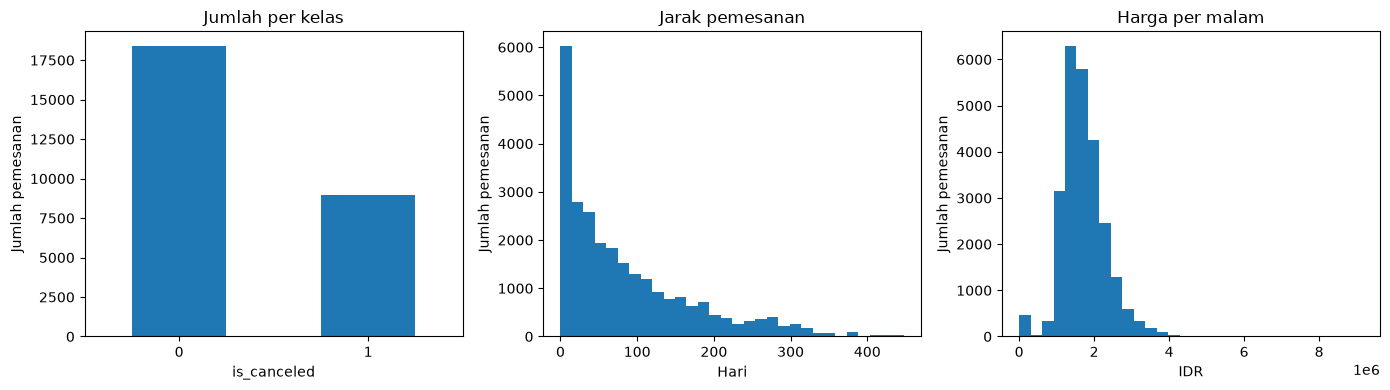

,jumlah
meal_package,
Breakfast,19654
Room Only,3713
Half Board,2242
NaN,1760
Full Board,4


,jumlah
room_category,
Type B,20447
Type G,4396
NaN,1002
Type A,699
Type D,514
Type C,189
Type F,119
Type E,7


,jumlah
booking_channel,
Online Travel Agent,17511
Offline Agent,7960
Corporate,1513
Complimentary,301
Airline,88


In [7]:
plot_distributions(train_df)
for kolom in ["meal_package", "room_category", "booking_channel"]:
    display(train_df[kolom].value_counts(dropna=False).rename("jumlah").to_frame())

**Hasil:** Kategori yang paling sering muncul adalah Breakfast pada paket makanan, Type B pada kategori kamar, dan Online Travel Agent pada kanal pemesanan. Beberapa kategori memiliki jumlah jauh lebih sedikit.


## Verify Data Quality

Pemeriksaan berikut merangkum nilai kosong, duplikasi baris lengkap, dan kemiripan fitur pada data training serta test.


In [8]:
display(check_data(train_df, test_df))

,baris,baris_dengan_nilai_kosong,duplikat_seluruh_kolom,fitur_sama_id_berbeda
data,,,,
train,27373,10737,0,66
test,6844,2669,0,3


**Hasil:** Tidak terdapat duplikasi baris lengkap pada kedua dataset. Sebanyak 10.737 baris training dan 2.669 baris test memiliki setidaknya satu nilai kosong. Terdapat pula kemiripan fitur dengan ID berbeda yang belum tentu merupakan kesalahan pencatatan.


---

# Training and Validation Split <a name="4"></a>

---

Pembagian stratifikasi menggunakan 80% data berlabel untuk training dan 20% untuk validasi. Data test tetap terpisah dari pemilihan model.


In [9]:
train_set, val_set = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["is_canceled"]
)
assert set(train_set["id"]).isdisjoint(val_set["id"])
assert len(train_set) + len(val_set) == len(train_df)
print("Training:", len(train_set), "| Validasi:", len(val_set))

Training: 21898 | Validasi: 5475


**Hasil:** Pembagian menghasilkan 21.898 baris training dan 5.475 baris validasi.


## Heatmap Korelasi (Tambahan)

Heatmap berikut memperlihatkan korelasi Pearson antara atribut numerik dan target pada bagian training. Korelasi menggambarkan hubungan linear dan tidak membuktikan sebab-akibat.


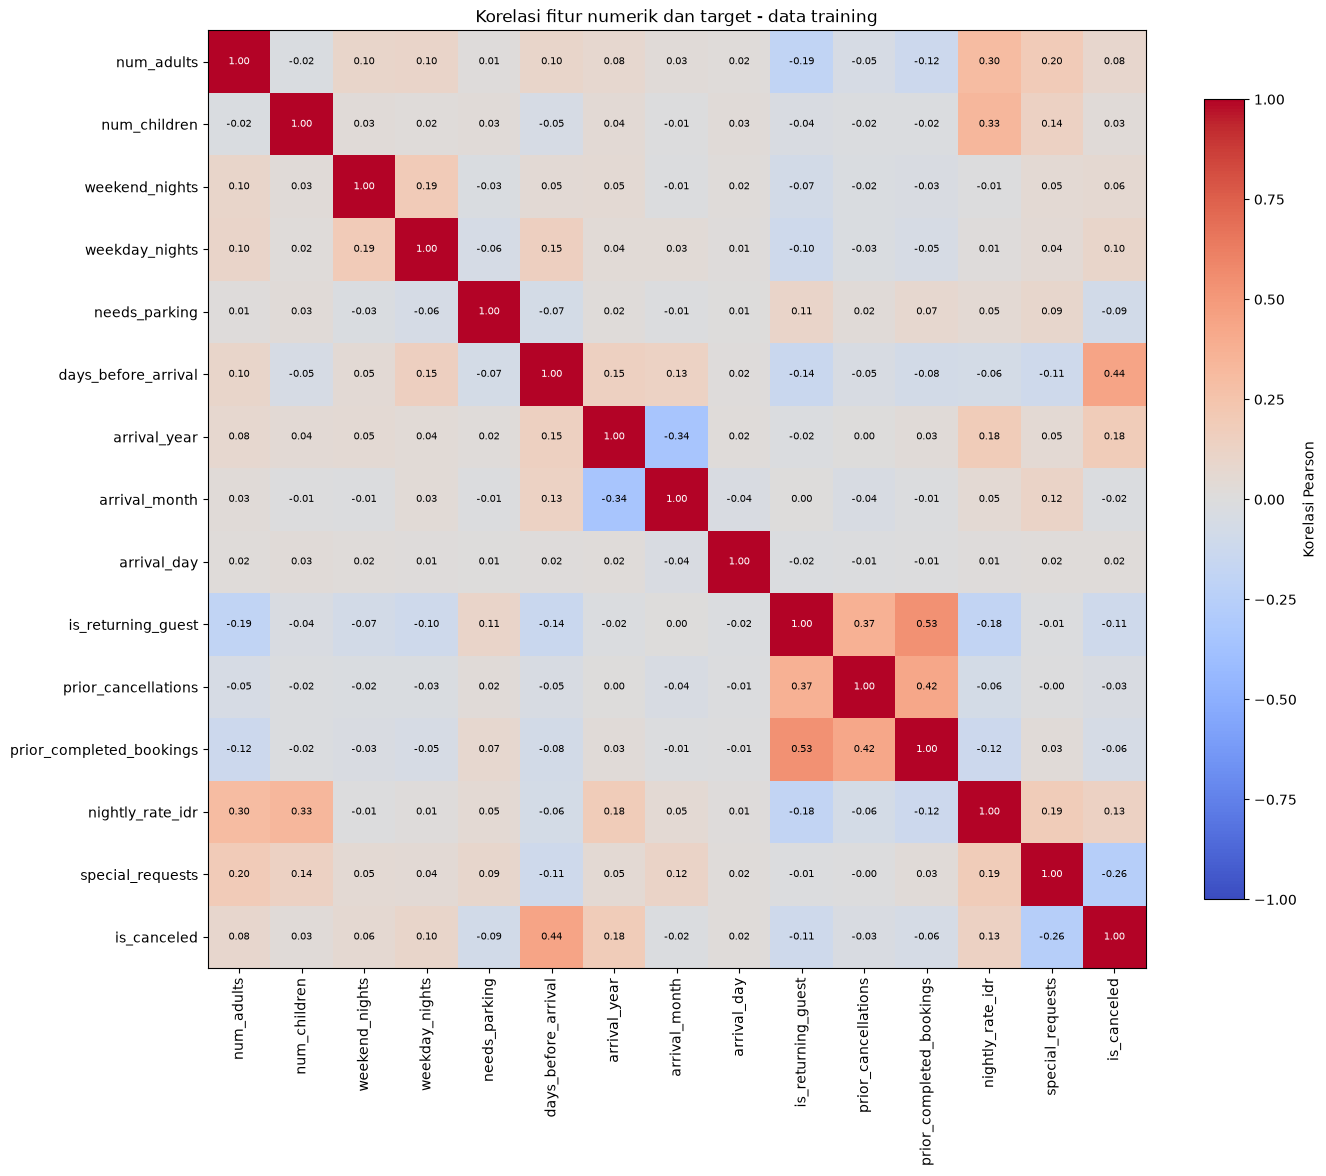

In [10]:
heatmap(train_set)

**Hasil:** Pada heatmap bagian training, `days_before_arrival` memiliki korelasi positif sekitar 0,44 dengan target, sedangkan `special_requests` memiliki korelasi negatif sekitar -0,26. Nilai tersebut tidak menunjukkan hubungan sebab-akibat.


---

# Data Preparation <a name="5"></a>

---

Tahap persiapan mengolah fitur melalui fungsi dalam modul preprocessing. Statistik transformasi dipelajari dari bagian training.


## Select Data

Pemisahan berikut menghasilkan fitur, label, dan ID test. Kolom `id` dan `is_canceled` tidak digunakan sebagai fitur.


In [11]:
X_train = train_set.drop(columns=["id", "is_canceled"])
y_train = train_set["is_canceled"].copy()
X_valid = val_set.drop(columns=["id", "is_canceled"])
y_valid = val_set["is_canceled"].copy()
X_test = test_df.drop(columns="id")
id_test = test_df["id"].copy()

kolom_numerik = X_train.select_dtypes(include="number").columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude="number").columns.tolist()
assert X_train.columns.equals(X_valid.columns) and X_train.columns.equals(X_test.columns)
print("Numerik:", kolom_numerik)
print("Kategori:", kolom_kategori)

Numerik: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Kategori: ['meal_package', 'room_category', 'booking_channel']


**Hasil:** Data memiliki 17 atribut masukan: 14 numerik dan tiga kategorikal. ID test disimpan terpisah untuk penyusunan submission.


## Clean Data

Kualitas data diperiksa melalui nilai kosong, duplikasi, nilai ekstrem, dan kesesuaian nilai atribut. Pipeline dasar mengisi nilai kosong tanpa menghapus baris.


### Missing Values

Tabel berikut menunjukkan jumlah nilai kosong dan nilai imputasi yang dihitung dari bagian training. Pipeline dasar menggunakan median untuk fitur numerik dan modus untuk fitur kategorikal.


In [12]:
display(missing_values(X_train, X_valid, X_test))
X_train_clean, X_valid_clean, X_test_clean, imputers = impute(X_train, X_valid, X_test)

,kosong_training,kosong_validasi,kosong_test,nilai_pengisi_training
num_adults,636,173,180,2.0
num_children,2426,609,747,0.0
weekend_nights,0,0,0,1.0
weekday_nights,0,0,0,2.0
meal_package,1403,357,442,Breakfast
needs_parking,885,197,247,0.0
room_category,810,192,242,Type B
days_before_arrival,877,246,290,57.0
arrival_year,0,0,0,2024.0
arrival_month,0,0,0,8.0


**Hasil:** Pada bagian training, median `num_children` adalah 0, median `days_before_arrival` adalah 57 hari, dan median `nightly_rate_idr` adalah Rp1.647.000. Nilai 0 yang sudah tercatat tetap dianggap valid; hanya nilai kosong yang diimputasi.


### Duplicates

Pemeriksaan berikut membedakan duplikasi baris lengkap dari kemiripan fitur pada pemesanan dengan ID berbeda.


In [13]:
display(duplicates(train_set, val_set, X_train, X_valid))

Duplikat lengkap training: 0
Duplikat lengkap validasi: 0
Fitur sama dalam training: 41
Fitur sama dalam validasi: 4


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
3315,3d8aaa46,2.0,0.0,2,0,Half Board,0.0,Type B,388.0,2024,10,22,Offline Agent,0,0,0,NaN,1.0,1
4140,a7e0ef46,1.0,0.0,0,2,Breakfast,0.0,Type B,156.0,2024,1,19,Offline Agent,0,0,0,1153000.0,0.0,0
21228,a84fd29c,2.0,0.0,0,2,Half Board,0.0,Type B,103.0,2023,10,16,Offline Agent,0,0,0,NaN,0.0,1
22671,3f675e87,2.0,0.0,0,1,Breakfast,0.0,Type B,NaN,2024,6,7,Offline Agent,0,0,0,NaN,0.0,0
7033,5c701cb0,1.0,0.0,2,4,Breakfast,0.0,Type B,247.0,2024,7,5,Offline Agent,0,0,0,NaN,0.0,1
19786,0f0a0e55,2.0,0.0,0,2,Half Board,0.0,Type B,43.0,2023,8,14,Offline Agent,0,0,0,NaN,0.0,0


**Hasil:** Tidak ditemukan duplikasi lengkap pada bagian training maupun validasi. Terdapat 41 baris fitur serupa dalam training dan empat dalam validasi; baris tersebut dipertahankan.


### Outliers

Metode IQR menandai nilai ekstrem pada harga, jarak pemesanan, dan lama menginap. Nilai yang ditandai tidak dihapus secara otomatis.


In [14]:
display(outliers(X_train, X_valid, X_test))

training | harga nol: 324 | total malam nol: 49
validasi | harga nol: 89 | total malam nol: 15
test | harga nol: 85 | total malam nol: 9


,batas_bawah,batas_atas,jumlah_di_luar_batas
nightly_rate_idr,314500.0,3046500.0,889
days_before_arrival,-145.0,287.0,755
weekend_nights,-3.0,5.0,13
weekday_nights,-2.0,6.0,201


**Hasil:** Pada bagian training, 889 nilai harga dan 755 nilai jarak pemesanan berada di luar batas IQR. Terdapat 324 harga nol dan 49 pemesanan dengan total malam nol; nilai tersebut tidak dihapus otomatis.


### Data Errors

Pemeriksaan mencakup bilangan nonnegatif, tanggal kalender, nilai biner, dan kategori yang diperbolehkan. Nilai kosong tetap diperbolehkan sebelum imputasi.


In [15]:
validate_values(X_train, X_valid, X_test)

training : pemeriksaan nilai valid lulus
validasi : pemeriksaan nilai valid lulus
test : pemeriksaan nilai valid lulus


**Hasil:** Pemeriksaan rentang dan kategori lulus pada bagian training, validasi, dan test.


## Construct Data

Tahap ini merangkum atribut turunan dan menyiapkan fitur melalui standardisasi dan encoding.


### Attribute Construction

Total tamu dan total malam dihitung sebagai ringkasan. Keduanya tidak ditambahkan ke masukan pipeline dasar.


In [16]:
ringkasan_pemesanan = pd.DataFrame({
    "total_tamu": X_train["num_adults"] + X_train["num_children"],
    "total_malam": X_train["weekend_nights"] + X_train["weekday_nights"],
})
display(ringkasan_pemesanan.describe().round(2))

,total_tamu,total_malam
count,18908.00,21898.00
mean,1.97,3.02
std,0.67,1.80
min,1.00,0.00
25%,2.00,2.00
50%,2.00,3.00
75%,2.00,4.00
max,12.00,24.00


**Hasil:** Median total tamu adalah dua orang dan median lama menginap tiga malam pada bagian training. Ringkasan total tamu menggunakan baris yang memiliki data jumlah tamu lengkap.


### Feature Scaling

Fitur numerik distandardisasi berdasarkan rata-rata dan simpangan baku dari data training. Parameter yang sama diterapkan pada validasi dan test.


In [17]:
X_train_scaled, X_valid_scaled, X_test_scaled, scaler = scale(
    X_train_clean, X_valid_clean, X_test_clean, kolom_numerik
)

### Encoding

One-hot encoding mengubah kategori menjadi kolom indikator dengan kategori yang dipelajari dari data training.


In [18]:
X_train_siap, X_valid_siap, X_test_siap, encoder = encode(
    X_train_scaled, X_valid_scaled, X_test_scaled
)
print("Jumlah fitur setelah encoding:", X_train_siap.shape[1])

Jumlah fitur setelah encoding: 30


**Hasil:** One-hot encoding menghasilkan 30 fitur pada pipeline dasar.


### Dimensionality Reduction

Jumlah atribut sebelum encoding ditampilkan sebagai acuan. Pipeline dasar tidak menggunakan PCA.


In [19]:
print("Jumlah fitur sebelum encoding:", X_train.shape[1])

Jumlah fitur sebelum encoding: 17


**Hasil:** Terdapat 17 atribut awal sebelum encoding.


## Class Balance

Distribusi label pada bagian training dan validasi diperiksa untuk melihat pengaruh stratifikasi. Pipeline dasar tidak melakukan oversampling atau undersampling.


In [20]:
display(pd.DataFrame({
    "jumlah_training": y_train.value_counts(),
    "proporsi_training": y_train.value_counts(normalize=True),
    "proporsi_validasi": y_valid.value_counts(normalize=True),
}).sort_index().round(4))

,jumlah_training,proporsi_training,proporsi_validasi
is_canceled,,,
0,14723,0.6723,0.6723
1,7175,0.3277,0.3277


**Hasil:** Proporsi kelas pada training dan validasi sama hingga empat desimal: 67,23% tidak dibatalkan dan 32,77% dibatalkan.


## Format Data

Pemeriksaan berikut memastikan kesesuaian indeks fitur dan label, urutan ID test, serta bentuk masukan awal.


In [21]:
assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)
assert id_test.equals(test_df["id"])
assert "id" not in X_train and "is_canceled" not in X_train
print("Bentuk input:", X_train.shape, X_valid.shape, X_test.shape)

Bentuk input: (21898, 17) (5475, 17) (6844, 17)


**Hasil:** Bentuk masukan awal adalah 21.898 x 17 untuk training, 5.475 x 17 untuk validasi, dan 6.844 x 17 untuk test.


---

# Preparation Pipeline <a name="6"></a>

---

Pipeline dasar menggabungkan imputasi, standardisasi, dan one-hot encoding. KNN dan SVM utama memakai pembobotan fitur Mutual Information; Logistic Regression menambahkan fitur turunan; Naive Bayes menggunakan diskritisasi dan kategori untuk nilai kosong. Parameter preprocessing dipelajari dari data training. Sel berikut memeriksa bentuk dan nilai fitur hasil pipeline dasar.


In [22]:
nama_fitur = X_train_siap.columns
assert X_train_siap.shape == (len(y_train), len(nama_fitur))
assert X_valid_siap.shape == (len(y_valid), len(nama_fitur))
assert X_test_siap.shape == (len(id_test), len(nama_fitur))
assert all(np.isfinite(data.to_numpy()).all() for data in [X_train_siap, X_valid_siap, X_test_siap])
print("Training:", X_train_siap.shape, "| Validasi:", X_valid_siap.shape, "| Test:", X_test_siap.shape)
display(X_train_siap.head())

Training: (21898, 30) | Validasi: (5475, 30) | Test: (6844, 30)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,...,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
3315,0.290096,-0.257497,1.350452,-1.547794,-0.174069,3.605815,0.469489,0.846720,0.736343,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9891,0.290096,-0.257497,0.207963,-0.139258,-0.174069,2.633313,0.469489,1.171684,-1.429894,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,-1.664525,-0.257497,-0.934527,-0.139258,-0.174069,0.972942,-2.129974,0.846720,-1.543907,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
41,0.290096,-0.257497,-0.934527,-0.139258,-0.174069,-0.651849,0.469489,1.496647,-1.657919,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
11576,0.290096,-0.257497,-0.934527,0.565009,-0.174069,-0.675568,0.469489,-0.778100,-0.745819,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


**Hasil:** Hasil pipeline dasar memiliki 30 fitur pada ketiga bagian data. Nilai numerik yang ditampilkan merupakan hasil standardisasi, sedangkan kolom kategori berisi indikator hasil encoding.


---

# Modeling and Validation <a name="7"></a>

---

Kelima algoritma diimplementasikan from scratch. Setiap sel berikut melatih model dan preprocessing yang sesuai; evaluasi pada bagian validasi disajikan setelah seluruh model dilatih.


## K-Nearest Neighbors

Sel berikut melatih KNN dengan `k=41`, jarak Manhattan, pembobotan jarak Shepard terregularisasi ($1 / (d + 0{,}3)^{2{,}5}$; Shepard, 1968), *local scaling* berbasis radius 15 tetangga training ($\alpha=0{,}5$, $\epsilon=0{,}1$; Zelnik-Manor & Perona, 2004; Schnitzer dkk., 2012) untuk mengurangi dominasi klaster padat (*hubness*), dan threshold `0,48`. Fitur diberi bobot Mutual Information tingkat grup kategori (`categorical_mi='group'`, `exponent=0,6`) dari data training. Konfigurasi model tersedia pada `KNN_PREP_CONFIG` dan `KNN_CONFIG`.

In [23]:
preprocessor_knn = KNNSVMPreprocessor(**KNN_PREP_CONFIG)
X_train_knn = preprocessor_knn.fit_transform(X_train, y_train)
X_valid_knn = preprocessor_knn.transform(X_valid)
model_knn = train_model(KNNFromScratch(**KNN_CONFIG), X_train_knn, y_train)

## Decision Tree Learning

Sel berikut melatih ID3 dengan cost-complexity pruning dan kalibrasi threshold pada bagian training. Konfigurasi model tersedia pada `DTL_CONFIG`.


In [24]:
model_dtl, preprocessor_dtl = train_dtl(X_train, y_train, **DTL_CONFIG)
X_valid_dtl = preprocessor_dtl.transform(X_valid)
print(f"Threshold DTL: {model_dtl.threshold}")

Threshold DTL: 0.38


**Hasil:** Threshold DTL pada pembagian validasi ini adalah 0,38. Nilai tersebut berasal dari kalibrasi di dalam data training.


## Logistic Regression

Sel berikut melatih Logistic Regression dengan fitur turunan, regularisasi L2, dan penurunan learning rate. Threshold dipilih menggunakan bagian kalibrasi di dalam data training.


In [25]:
param_lr_config = dict(
    penalty="l2", lam=1e-4, lr=0.05, lr_decay=0.05,
    n_epoch=80, batch_size=64, random_state=SEED,
)
# Kalibrasi threshold menggunakan bagian dalam data training
X_lr_it, X_lr_ic, y_lr_it, y_lr_ic = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
prep_lr_cal = LRFeaturePreprocessor()
model_lr_cal = train_model(
    LogisticRegression(**param_lr_config), prep_lr_cal.fit_transform(X_lr_it), y_lr_it
)
th_lr_val, _ = calibrate_threshold(y_lr_ic, model_lr_cal.predict_proba(prep_lr_cal.transform(X_lr_ic)))

preprocessor_lr = LRFeaturePreprocessor()
X_train_lr = preprocessor_lr.fit_transform(X_train)
X_valid_lr = preprocessor_lr.transform(X_valid)
param_lr = {**param_lr_config, "threshold": th_lr_val}
model_lr = train_model(LogisticRegression(**param_lr), X_train_lr, y_train)
print(f"Threshold kalibrasi inner split LR: {th_lr_val:.3f} | Epoch: {len(model_lr.loss_history_)} | Loss akhir: {model_lr.loss_history_[-1]:.5f}")

Threshold kalibrasi inner split LR: 0.415 | Epoch: 80 | Loss akhir: 0.40911


**Hasil:** Threshold LR pada pembagian ini adalah 0,415. Pelatihan berlangsung selama 80 epoch dengan loss akhir yang tercatat sebesar 0,40911.


## Support Vector Machine

Sel berikut melatih SVM dengan kernel linear, polynomial, dan Gaussian/RBF. Model RBF menggunakan pembobotan fitur Mutual Information dan threshold -0,2. Pemilihan working set mengikuti Fan, Chen, dan Lin (2005).


In [26]:
# Kernel linear menggunakan data terproses standar.
model_svm_linear = train_model(
    WorkingSetSVM(C=1.0, kernel="linear", tol=0.01, max_iter=200000, cache_mb=512),
    X_train_siap, y_train,
)
if not model_svm_linear.converged_:
    raise RuntimeError("SVM Linear belum konvergen")

# Kernel polynomial menggunakan derajat dua.
model_svm_poly = train_model(
    WorkingSetSVM(C=1.0, kernel="polynomial", degree=2, coef0=1.0, tol=0.01, max_iter=200000, cache_mb=512),
    X_train_siap, y_train,
)
if not model_svm_poly.converged_:
    raise RuntimeError("SVM Polynomial belum konvergen")

# Kernel RBF menggunakan pembobotan fitur.
preprocessor_svm = KNNSVMPreprocessor(
    exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=SEED
)
X_train_svm = preprocessor_svm.fit_transform(X_train, y_train)
X_valid_svm = preprocessor_svm.transform(X_valid)
model_svm = train_model(
    WorkingSetSVM(C=4, gamma=0.16, kernel="rbf", tol=0.003,
                  max_iter=200000, cache_mb=512, threshold=-0.2),
    X_train_svm, y_train,
)
if not model_svm.converged_:
    raise RuntimeError("SVM RBF belum konvergen")
print(f"Konvergen | Linear iter={model_svm_linear.n_iter_}, Poly iter={model_svm_poly.n_iter_}, RBF iter={model_svm.n_iter_}")

Konvergen | Linear iter=82386, Poly iter=17461, RBF iter=34687


**Hasil:** Ketiga model mencapai kondisi konvergen sesuai pemeriksaan pada implementasi. Perbandingan kinerja masing-masing kernel disajikan pada bagian scikit-learn.


## Naive Bayes

Sel berikut melatih Naive Bayes pada fitur yang didiskritisasi berdasarkan kuantil training. Nilai kosong direpresentasikan sebagai kategori tersendiri.


In [27]:
preprocessor_nb = NaiveBayesPreprocessor(discretize=True, n_bins=15)
X_train_nb = preprocessor_nb.fit_transform(X_train)
X_valid_nb = preprocessor_nb.transform(X_valid)
model_nb = train_model(NaiveBayes(), X_train_nb, y_train)
print("Fitur Naive Bayes:", list(X_train_nb.columns))


Fitur Naive Bayes: ['year_month', 'meal_package', 'room_category', 'booking_channel', 'num_adults', 'num_children', 'weekend_nights', 'needs_parking', 'special_requests', 'prior_cancel_bin', 'prior_comp_bin', 'weekday_nights_bin', 'rate_is_zero', 'total_nights_zero', 'days_before_arrival_bin', 'nightly_rate_idr_bin', 'arrival_day_bin']


**Hasil:** Preprocessing menghasilkan 17 fitur kategorikal atau hasil diskritisasi untuk Naive Bayes.


## Model Evaluation

Evaluasi berikut membandingkan kelima model pada data validasi yang sama menggunakan Macro F1, akurasi, precision, recall, dan confusion matrix.


In [28]:
evaluasi_semua = [
    ("KNN", model_knn, X_valid_knn),
    ("DTL", model_dtl, X_valid_dtl),
    ("LR", model_lr, X_valid_lr),
    ("SVM", model_svm, X_valid_svm),
    ("NB", model_nb, X_valid_nb),
]

ringkasan_eval = {}
confusion_utama = {}
for nama, model, X_model in evaluasi_semua:
    hasil, cm = evaluate_model(model, X_model, y_valid)
    ringkasan_eval[nama] = hasil
    confusion_utama[nama] = cm

df_eval = pd.DataFrame(ringkasan_eval).T.sort_values("macro_f1", ascending=False)
display(df_eval.round(4))

for nama, cm in confusion_utama.items():
    print(f"\nConfusion Matrix - {nama}")
    display(cm)


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
KNN,0.8789,0.8278,0.7960,0.9108,0.8116,0.8612
SVM,0.8628,0.7972,0.7798,0.8985,0.7884,0.8435
DTL,0.8517,0.7654,0.7893,0.8889,0.7772,0.8330
LR,0.8089,0.7009,0.7274,0.8566,0.7139,0.7852
NB,0.7863,0.6886,0.6349,0.8440,0.6607,0.7524



Confusion Matrix - KNN


,prediksi 0,prediksi 1
aktual 0,3384,297
aktual 1,366,1428



Confusion Matrix - DTL


,prediksi 0,prediksi 1
aktual 0,3247,434
aktual 1,378,1416



Confusion Matrix - LR


,prediksi 0,prediksi 1
aktual 0,3124,557
aktual 1,489,1305



Confusion Matrix - SVM


,prediksi 0,prediksi 1
aktual 0,3325,356
aktual 1,395,1399



Confusion Matrix - NB


,prediksi 0,prediksi 1
aktual 0,3166,515
aktual 1,655,1139


**Hasil:** Pada validasi ini, Macro F1 tertinggi diperoleh KNN sebesar 0,8612, diikuti SVM 0,8435 dan DTL 0,8330. Nilai LR dan NB masing-masing sebesar 0,7852 dan 0,7524. Hasil ini hanya berlaku untuk pembagian validasi yang digunakan.

## Improvements (Optional)

Cross-validation digunakan untuk melihat variasi hasil pada beberapa pembagian data berlabel.


### Stratified 5-Fold Cross-Validation

Pada setiap fold, proporsi kelas dijaga dan preprocessing dipelajari ulang dari bagian training fold. Proses ini menggunakan konfigurasi model yang sama dengan evaluasi utama.


In [29]:
RUN_SVM_CV = True
X_cv = train_df.drop(columns=["id", "is_canceled"])
y_cv = train_df["is_canceled"].to_numpy()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_cv, y_cv), 1):
    X_tr_f, y_tr_f = X_cv.iloc[tr_idx], y_cv[tr_idx]
    X_va_f, y_va_f = X_cv.iloc[va_idx], y_cv[va_idx]

    p_k = KNNSVMPreprocessor(**KNN_PREP_CONFIG)
    m_k = KNNFromScratch(**KNN_CONFIG).fit(p_k.fit_transform(X_tr_f, y_tr_f), y_tr_f)
    s_k, _ = evaluate_model(m_k, p_k.transform(X_va_f), y_va_f)
    cv_rows.append({"model": "KNN", "fold": fold, **s_k.to_dict()})

    m_d, p_d = train_dtl(X_tr_f, y_tr_f, **DTL_CONFIG)
    s_d, _ = evaluate_model(m_d, p_d.transform(X_va_f), y_va_f)
    cv_rows.append({"model": "DTL", "fold": fold, **s_d.to_dict()})

    X_it, X_ic, y_it, y_ic = train_test_split(
        X_tr_f, y_tr_f, test_size=0.2, random_state=SEED, stratify=y_tr_f
    )
    p_li = LRFeaturePreprocessor()
    m_li = LogisticRegression(**param_lr_config).fit(p_li.fit_transform(X_it), y_it)
    th_f, _ = calibrate_threshold(y_ic, m_li.predict_proba(p_li.transform(X_ic)))
    p_l = LRFeaturePreprocessor()
    m_l = LogisticRegression(**param_lr_config, threshold=th_f).fit(p_l.fit_transform(X_tr_f), y_tr_f)
    s_l, _ = evaluate_model(m_l, p_l.transform(X_va_f), y_va_f)
    cv_rows.append({"model": "LR", "fold": fold, **s_l.to_dict()})

    p_n = NaiveBayesPreprocessor(discretize=True, n_bins=15)
    m_n = NaiveBayes().fit(p_n.fit_transform(X_tr_f), y_tr_f)
    s_n, _ = evaluate_model(m_n, p_n.transform(X_va_f), y_va_f)
    cv_rows.append({"model": "NB", "fold": fold, **s_n.to_dict()})

    if RUN_SVM_CV:
        p_s = KNNSVMPreprocessor(exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=SEED)
        m_s = WorkingSetSVM(C=4, gamma=0.16, kernel="rbf", tol=0.003, max_iter=200000, cache_mb=512, threshold=-0.2).fit(p_s.fit_transform(X_tr_f, y_tr_f), y_tr_f)
        s_s, _ = evaluate_model(m_s, p_s.transform(X_va_f), y_va_f)
        cv_rows.append({"model": "SVM", "fold": fold, **s_s.to_dict()})

df_cv = pd.DataFrame(cv_rows)
ringkasan_cv = df_cv.groupby("model").agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"),
    f1_kelas_0_mean=("f1_kelas_0", "mean"),
    f1_kelas_1_mean=("f1_kelas_1", "mean"),
).sort_values("macro_f1_mean", ascending=False)
display(ringkasan_cv.round(4))

print("Macro F1 per fold:")
display(df_cv.pivot(index="model", columns="fold", values="macro_f1").reindex(ringkasan_cv.index).round(4))


,macro_f1_mean,macro_f1_std,accuracy_mean,f1_kelas_0_mean,f1_kelas_1_mean
model,,,,,
KNN,0.8610,0.0043,0.8793,0.9114,0.8106
SVM,0.8465,0.0069,0.8655,0.9006,0.7924
DTL,0.8346,0.0045,0.8542,0.8915,0.7777
LR,0.7873,0.0034,0.8134,0.8618,0.7128
NB,0.7514,0.0022,0.7872,0.8458,0.6569


Macro F1 per fold:


fold,1,2,3,4,5
model,,,,,
KNN,0.8636,0.8643,0.8589,0.8544,0.8638
SVM,0.8492,0.8562,0.8428,0.8378,0.8463
DTL,0.8351,0.8373,0.8400,0.8290,0.8313
LR,0.7845,0.7864,0.7932,0.7859,0.7864
NB,0.7501,0.7546,0.7509,0.7488,0.7524


**Hasil:** Rata-rata Macro F1 tertinggi pada lima fold diperoleh KNN sebesar 0,8610 dengan simpangan baku 0,0043, diikuti SVM 0,8465 (simpangan baku 0,0069) dan DTL 0,8346 (simpangan baku 0,0045). Hasil cross-validation tidak menjamin skor private leaderboard yang sama.

---

# Comparison with scikit-learn <a name="8"></a>

---

Perbandingan berikut menggunakan data dan representasi fitur yang sama untuk implementasi from scratch dan scikit-learn. Perbedaan cara optimasi dan pembentukan model dapat menghasilkan prediksi yang berbeda.


## Perbandingan DTL dengan scikit-learn

ID3 dibandingkan dengan `DecisionTreeClassifier` ber-kriteria entropy pada fitur yang sama. Kedua implementasi menerapkan pruning sesuai mekanisme masing-masing.


In [30]:
model_dtl_sklearn = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=DTL_CONFIG["max_depth"],
    min_samples_split=DTL_CONFIG["min_samples_split"],
    ccp_alpha=DTL_CONFIG["ccp_alpha"] or 0.0,
    random_state=SEED,
)
hasil_perbandingan_dtl = compare_models(
    model_dtl, model_dtl_sklearn,
    preprocessor_dtl.transform(X_train), y_train,
    X_valid_dtl, y_valid, threshold=model_dtl.threshold,
)
display(hasil_perbandingan_dtl.round(4))

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8517,0.7654,0.7893,0.8889,0.7772,0.8330
scikit-learn,0.8515,0.7650,0.7893,0.8887,0.7770,0.8328


**Hasil:** Macro F1 DTL from scratch sebesar 0,8330, sedangkan scikit-learn sebesar 0,8328 pada validasi ini.


## Perbandingan Logistic Regression dengan scikit-learn

Logistic Regression dengan regularisasi L2 dibandingkan pada fitur turunan dan threshold yang sama. Kekuatan regularisasi scikit-learn disesuaikan dengan parameter model from scratch.


In [31]:
model_lr_sklearn = SkLogisticRegression(
    C=1.0 / (len(X_train_lr) * model_lr.lam),
    solver="lbfgs", max_iter=2000, random_state=SEED,
)
display(compare_models(
    model_lr, model_lr_sklearn, X_train_lr, y_train, X_valid_lr, y_valid,
    threshold=model_lr.threshold,
).round(4))


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8089,0.7009,0.7274,0.8566,0.7139,0.7852
scikit-learn,0.8099,0.7004,0.7336,0.8569,0.7166,0.7868


**Hasil:** Macro F1 Logistic Regression from scratch sebesar 0,7852 dan scikit-learn sebesar 0,7868 pada validasi ini.


## Perbandingan SVM dengan scikit-learn (Ketiga Kernel)

SVM from scratch dan `SVC` dibandingkan pada kernel linear, polynomial, dan RBF dengan konfigurasi serta fitur yang sesuai.


In [32]:
print("SVM Kernel Linear")
display(compare_models(
    model_svm_linear,
    SVC(C=1.0, kernel="linear", tol=0.01, cache_size=512),
    X_train_siap, y_train, X_valid_siap, y_valid,
).round(4))

print("\nSVM Kernel Polynomial (degree=2, coef0=1.0)")
display(compare_models(
    model_svm_poly,
    SVC(C=1.0, kernel="poly", degree=2, coef0=1.0, tol=0.01, cache_size=512),
    X_train_siap, y_train, X_valid_siap, y_valid,
).round(4))

print("\nSVM Kernel Gaussian / RBF (KNNSVMPreprocessor, threshold=-0.2)")
display(compare_models(
    model_svm,
    SVC(C=4, gamma=0.16, kernel="rbf", tol=0.003, cache_size=512),
    X_train_svm, y_train, X_valid_svm, y_valid, threshold=-0.2,
).round(4))

SVM Kernel Linear


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.7967,0.7366,0.5909,0.8558,0.6557,0.7558
scikit-learn,0.7967,0.7370,0.5903,0.8558,0.6555,0.7557



SVM Kernel Polynomial (degree=2, coef0=1.0)


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8141,0.7694,0.6176,0.8681,0.6852,0.7766
scikit-learn,0.8137,0.7684,0.6176,0.8678,0.6848,0.7763



SVM Kernel Gaussian / RBF (KNNSVMPreprocessor, threshold=-0.2)


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8628,0.7972,0.7798,0.8985,0.7884,0.8435
scikit-learn,0.8626,0.7970,0.7793,0.8984,0.7880,0.8432


**Hasil:** Pada hasil yang ditampilkan, kernel RBF memperoleh Macro F1 tertinggi di antara ketiga kernel SVM: 0,8435 untuk implementasi from scratch dan 0,8432 untuk scikit-learn.


## Perbandingan KNN dengan scikit-learn

Kedua implementasi dibandingkan pada fitur `X_train_knn`, jarak Manhattan, `k=41`, bobot Shepard terregularisasi ($1 / (d + 0{,}3)^{2{,}5}$), dan threshold `0,48` sesuai `KNN_CONFIG`. Implementasi *from scratch* menyertakan *local scaling* (`local_scale_k=15`, `local_scale_alpha=0,5`, `local_scale_eps=0,1`) yang belum tersedia secara bawaan pada `KNeighborsClassifier`.

In [33]:
def bobot_shepard(distances):
    return 1.0 / ((distances + KNN_CONFIG["weight_eps"]) ** KNN_CONFIG["weight_power"])

model_knn_sklearn = KNeighborsClassifier(
    n_neighbors=KNN_CONFIG["k"],
    metric=KNN_CONFIG["metric"],
    weights=bobot_shepard,
    algorithm="brute",
)
display(compare_models(
    model_knn, model_knn_sklearn, X_train_knn, y_train, X_valid_knn, y_valid,
    threshold=KNN_CONFIG["threshold"],
).round(4))

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8789,0.8278,0.7960,0.9108,0.8116,0.8612
scikit-learn,0.8725,0.8131,0.7932,0.9058,0.8030,0.8544


**Hasil:** Pada validasi ini, KNN *from scratch* dengan *local scaling* memperoleh Macro F1 sebesar 0,8612 (F1 kelas 1: 0,8116), lebih tinggi dibandingkan `KNeighborsClassifier` *scikit-learn* tanpa *local scaling* sebesar 0,8544 (F1 kelas 1: 0,8030).

## Perbandingan Naive Bayes dengan scikit-learn

Kedua implementasi dibandingkan menggunakan fitur hasil diskritisasi. Kategori yang tidak ditemukan pada training dikecualikan dari evaluasi scikit-learn.


In [34]:
# Perbandingan CategoricalNB pada fitur terdiskritisasi
encoder_nb_disc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
train_disc_enc = encoder_nb_disc.fit_transform(X_train_nb).astype(int)
valid_disc_enc = encoder_nb_disc.transform(X_valid_nb).astype(int)
n_cats_train = np.array([len(c) for c in encoder_nb_disc.categories_])
mask_dikenal = (valid_disc_enc >= 0).all(axis=1)
X_tr_cnb = pd.DataFrame(train_disc_enc, columns=X_train_nb.columns)
X_va_cnb = pd.DataFrame(valid_disc_enc[mask_dikenal], columns=X_valid_nb.columns)
y_va_cnb = y_valid.iloc[mask_dikenal]

model_kat_scratch = train_model(NaiveBayes(), X_tr_cnb, y_train)
model_kat_sklearn = CategoricalNB(alpha=1, min_categories=n_cats_train)
print(f"\nNaive Bayes vs CategoricalNB (baris validasi dengan kategori dikenal: {mask_dikenal.sum()}/{len(y_valid)})")
display(compare_models(model_kat_scratch, model_kat_sklearn, X_tr_cnb, y_train, X_va_cnb, y_va_cnb).round(4))
print("Selisih peluang maksimum:", np.abs(model_kat_scratch.predict_proba(X_va_cnb) - model_kat_sklearn.predict_proba(X_va_cnb)).max())


Naive Bayes vs CategoricalNB (baris validasi dengan kategori dikenal: 5475/5475)


,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.7863,0.6886,0.6349,0.844,0.6607,0.7524
scikit-learn,0.7863,0.6886,0.6349,0.844,0.6607,0.7524


Selisih peluang maksimum: 7.105427357601002e-15


**Hasil:** Seluruh 5.475 baris validasi memiliki kategori yang dikenal. Kedua implementasi memperoleh Macro F1 0,7524; selisih maksimum probabilitas yang tercatat sekitar 7,1 x 10^-15.


---

# Saving and Loading Models <a name="9"></a>

---

Sel pada bagian ini melatih ulang masing-masing model menggunakan seluruh `train.csv`, menyimpan model beserta preprocessor, lalu memeriksa hasil pemuatan ulang pada sampel data test.


## Model Final Decision Tree Learning

Sel berikut melatih dan menyimpan DTL dengan `DTL_CONFIG` pada seluruh data berlabel.


In [35]:
X_lengkap = train_df.drop(columns=["id", "is_canceled"])
y_lengkap = train_df["is_canceled"]
output_dtl = root / "output" / "DTL"
model_dtl_final, preprocessor_dtl_final = train_dtl(X_lengkap, y_lengkap, **DTL_CONFIG)
save_model(model_dtl_final, preprocessor_dtl_final, output_dtl, "dtl")
model_dtl_muat, preprocessor_dtl_muat = load_model(output_dtl, "dtl")
assert np.array_equal(
    model_dtl_final.predict(preprocessor_dtl_final.transform(X_test.head(20))),
    model_dtl_muat.predict(preprocessor_dtl_muat.transform(X_test.head(20))),
)
print(f"Model DTL final berhasil disimpan dan dimuat (threshold={model_dtl_muat.threshold}).")

Model DTL final berhasil disimpan dan dimuat (threshold=0.45999999999999996).


**Hasil:** Model dan preprocessor DTL berhasil disimpan dan dimuat kembali. Threshold final yang tercatat adalah 0,46.


## Model Final Logistic Regression

Threshold dikalibrasi pada bagian data training, kemudian model dan preprocessor dilatih ulang menggunakan seluruh data berlabel.


In [36]:
X_lrf_it, X_lrf_ic, y_lrf_it, y_lrf_ic = train_test_split(
    X_lengkap, y_lengkap, test_size=0.2, random_state=SEED, stratify=y_lengkap
)
prep_lrf_cal = LRFeaturePreprocessor()
m_lrf_cal = train_model(LogisticRegression(**param_lr_config), prep_lrf_cal.fit_transform(X_lrf_it), y_lrf_it)
th_lr_final, _ = calibrate_threshold(y_lrf_ic, m_lrf_cal.predict_proba(prep_lrf_cal.transform(X_lrf_ic)))

preprocessor_lr_final = LRFeaturePreprocessor()
X_lengkap_lr = preprocessor_lr_final.fit_transform(X_lengkap, y_lengkap)
model_lr_final = train_model(LogisticRegression(**param_lr_config, threshold=th_lr_final), X_lengkap_lr, y_lengkap)

output_lr = root / "output" / "Logistic_Regression"
save_model(model_lr_final, preprocessor_lr_final, output_lr, "lr")
model_lr_muat, preprocessor_lr_muat = load_model(output_lr, "lr")
assert np.array_equal(
    model_lr_final.predict(preprocessor_lr_final.transform(X_test.head(20))),
    model_lr_muat.predict(preprocessor_lr_muat.transform(X_test.head(20))),
)
print(f"Model LR final berhasil disimpan dan dimuat (threshold={model_lr_muat.threshold:.3f}).")

Model LR final berhasil disimpan dan dimuat (threshold=0.480).


**Hasil:** Model dan preprocessor Logistic Regression berhasil disimpan dan dimuat kembali. Threshold final yang tercatat adalah 0,48.


## Model Final Support Vector Machine

Sel berikut melatih dan menyimpan SVM RBF beserta preprocessor pada seluruh data berlabel.


In [37]:
preprocessor_svm_final = KNNSVMPreprocessor(
    exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=SEED
)
X_lengkap_svm = preprocessor_svm_final.fit_transform(X_lengkap, y_lengkap)
model_svm_final = train_model(
    WorkingSetSVM(C=4, gamma=0.16, kernel="rbf", tol=0.003,
                  max_iter=200000, cache_mb=512, threshold=-0.2),
    X_lengkap_svm, y_lengkap,
)
if not model_svm_final.converged_:
    raise RuntimeError("SVM final belum konvergen")

output_svm = root / "output" / "SVM"
save_model(model_svm_final, preprocessor_svm_final, output_svm, "svm")
model_svm_muat, preprocessor_svm_muat = load_model(output_svm, "svm")
assert np.array_equal(
    model_svm_final.predict(preprocessor_svm_final.transform(X_test.head(20))),
    model_svm_muat.predict(preprocessor_svm_muat.transform(X_test.head(20))),
)
print(f"Model SVM final berhasil disimpan dan dimuat (n_support={model_svm_muat.n_support_}, iter={model_svm_muat.n_iter_}).")

Model SVM final berhasil disimpan dan dimuat (n_support=10726, iter=44535).


**Hasil:** Model dan preprocessor SVM berhasil disimpan dan dimuat kembali; hasil pemeriksaan konvergensi model final juga ditampilkan.


## Model Final K-Nearest Neighbors

Sel berikut melatih dan menyimpan KNN beserta preprocessor berbobot Mutual Information menggunakan `KNN_PREP_CONFIG` dan `KNN_CONFIG` pada seluruh data berlabel.

In [38]:
preprocessor_knn_final = KNNSVMPreprocessor(**KNN_PREP_CONFIG)
X_lengkap_knn = preprocessor_knn_final.fit_transform(X_lengkap, y_lengkap)
model_knn_final = train_model(KNNFromScratch(**KNN_CONFIG), X_lengkap_knn, y_lengkap)

output_knn = root / "output" / "KNN"
save_model(model_knn_final, preprocessor_knn_final, output_knn, "knn")
model_knn_muat, preprocessor_knn_muat = load_model(output_knn, "knn")
assert np.array_equal(
    model_knn_final.predict(preprocessor_knn_final.transform(X_test.head(20))),
    model_knn_muat.predict(preprocessor_knn_muat.transform(X_test.head(20))),
)
print("Model KNN final dan preprocessor berhasil disimpan dan dimuat.")

Model KNN final dan preprocessor berhasil disimpan dan dimuat.


**Hasil:** Model dan preprocessor KNN berhasil disimpan dan dimuat kembali.


## Model Final Naive Bayes

Sel berikut melatih dan menyimpan Naive Bayes beserta preprocessor yang menggunakan diskritisasi kuantil.


In [39]:
preprocessor_nb_final = NaiveBayesPreprocessor(discretize=True, n_bins=15)
X_lengkap_nb = preprocessor_nb_final.fit_transform(X_lengkap)
model_nb_final = train_model(NaiveBayes(), X_lengkap_nb, y_lengkap)

output_nb = root / "output" / "Naive_Bayes"
save_model(model_nb_final, preprocessor_nb_final, output_nb, "nb")
model_nb_muat, preprocessor_nb_muat = load_model(output_nb, "nb")
assert np.array_equal(
    model_nb_final.predict(preprocessor_nb_final.transform(X_test.head(20))),
    model_nb_muat.predict(preprocessor_nb_muat.transform(X_test.head(20))),
)
print("Model Naive Bayes final dan preprocessor berhasil disimpan dan dimuat.")

Model Naive Bayes final dan preprocessor berhasil disimpan dan dimuat.


**Hasil:** Model dan preprocessor Naive Bayes berhasil disimpan dan dimuat kembali.


---

# Kaggle Submission <a name="10"></a>

---

Sel berikut menghasilkan submission untuk setiap model menggunakan model dan preprocessor yang telah dimuat. Setiap berkas berisi kolom `id` dan `is_canceled`.


In [40]:
assert id_test.equals(test_df["id"])
models_submission = {
    "knn": (model_knn_muat, preprocessor_knn_muat, output_knn),
    "svm": (model_svm_muat, preprocessor_svm_muat, output_svm),
    "dtl": (model_dtl_muat, preprocessor_dtl_muat, output_dtl),
    "lr": (model_lr_muat, preprocessor_lr_muat, output_lr),
    "nb": (model_nb_muat, preprocessor_nb_muat, output_nb),
}

ringkasan_sub = []
for name, (model, preprocessor, output_dir) in models_submission.items():
    submission = submit_model(model, preprocessor, X_test, id_test, output_dir, name)
    assert submission["id"].equals(submission_example["id"])
    ringkasan_sub.append({
        "model": name.upper(),
        "file": str((output_dir / f"submission_{name}.csv").relative_to(root)),
        "baris": len(submission),
        "proporsi_prediksi_1": submission["is_canceled"].mean(),
        "proporsi_train_1": y_lengkap.mean(),
    })
    display(submission.head(3))

display(pd.DataFrame(ringkasan_sub).set_index("model").round(4))

,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1


,file,baris,proporsi_prediksi_1,proporsi_train_1
model,,,,
KNN,output\KNN\submission_knn.csv,6844,0.3011,0.3277
SVM,output\SVM\submission_svm.csv,6844,0.3102,0.3277
DTL,output\DTL\submission_dtl.csv,6844,0.3212,0.3277
LR,output\Logistic_Regression\submission_lr.csv,6844,0.2978,0.3277
NB,output\Naive_Bayes\submission_nb.csv,6844,0.2848,0.3277


**Hasil:** Setiap submission memiliki 6.844 baris. Proporsi prediksi pembatalan berbeda antar model; proporsi tersebut bukan ukuran akurasi karena label test tidak tersedia.


---

# Error Analysis <a name="11"></a>

---

## Confusion Matrix Setiap Model

Tabel berikut merangkum prediksi benar dan salah pada data validasi. TN dan TP adalah prediksi benar untuk kelas 0 dan 1; FP dan FN adalah prediksi salah untuk kelas 1 dan 0.


In [41]:
model_validasi = {
    "KNN": (model_knn, X_valid_knn),
    "DTL": (model_dtl, X_valid_dtl),
    "Logistic Regression": (model_lr, X_valid_lr),
    "SVM": (model_svm, X_valid_svm),
    "Naive Bayes": (model_nb, X_valid_nb),
}
hasil_confusion = []
for nama, (model, fitur) in model_validasi.items():
    tn, fp, fn, tp = confusion_matrix(y_valid, model.predict(fitur), labels=[0, 1]).ravel()
    hasil_confusion.append({"model": nama, "TN": tn, "FP": fp, "FN": fn, "TP": tp})

tabel_confusion = pd.DataFrame(hasil_confusion).set_index("model")
assert (tabel_confusion.sum(axis=1) == len(y_valid)).all()
display(tabel_confusion)

,TN,FP,FN,TP
model,,,,
KNN,3384,297,366,1428
DTL,3247,434,378,1416
Logistic Regression,3124,557,489,1305
SVM,3325,356,395,1399
Naive Bayes,3166,515,655,1139


**Hasil:** Pada validasi, KNN menghasilkan 297 false positive dan 366 false negative. Jumlah masing-masing jenis kesalahan berbeda pada setiap model dan perlu dipertimbangkan sesuai kebutuhan penggunaan.

## Analisis Kesalahan per Subgrup (Tambahan)

Kesalahan KNN dan SVM diperiksa berdasarkan kanal pemesanan, jarak kedatangan, dan keberadaan nilai kosong pada data validasi.


In [42]:
pred_knn_val = model_knn.predict(X_valid_knn)
pred_svm_val = model_svm.predict(X_valid_svm)
err_knn = (pred_knn_val != y_valid.to_numpy())
err_svm = (pred_svm_val != y_valid.to_numpy())

print(f"KNN             | Error rate: {err_knn.mean():.4f} | FP={((pred_knn_val==1)&(y_valid==0)).sum()} | FN={((pred_knn_val==0)&(y_valid==1)).sum()}")
print(f"SVM RBF    | Error rate: {err_svm.mean():.4f} | FP={((pred_svm_val==1)&(y_valid==0)).sum()} | FN={((pred_svm_val==0)&(y_valid==1)).sum()}")

val_diag = X_valid.copy()
val_diag["err_knn"] = err_knn
val_diag["err_svm"] = err_svm
val_diag["y"] = y_valid.to_numpy()

print("\nError rate per booking_channel:")
display(val_diag.groupby("booking_channel").agg(
    n=("y", "size"), cancel_rate=("y", "mean"),
    err_knn=("err_knn", "mean"), err_svm=("err_svm", "mean"),
).round(4))

print("\nError rate per bucket days_before_arrival:")
dba_bucket = pd.cut(val_diag["days_before_arrival"], [-1, 15, 60, 150, 500])
display(val_diag.groupby(dba_bucket, observed=False).agg(
    n=("y", "size"), cancel_rate=("y", "mean"),
    err_knn=("err_knn", "mean"), err_svm=("err_svm", "mean"),
).round(4))

print("\nError rate berdasarkan nilai kosong fitur utama:")
miss_err = []
for col in ["days_before_arrival", "special_requests", "nightly_rate_idr", "room_category", "meal_package"]:
    m = val_diag[col].isna()
    miss_err.append({
        "kolom": col, "n_kosong": int(m.sum()),
        "cancel_kosong": val_diag.loc[m, "y"].mean(),
        "err_knn_kosong": val_diag.loc[m, "err_knn"].mean(),
        "err_knn_terisi": val_diag.loc[~m, "err_knn"].mean(),
        "err_svm_kosong": val_diag.loc[m, "err_svm"].mean(),
        "err_svm_terisi": val_diag.loc[~m, "err_svm"].mean(),
    })
display(pd.DataFrame(miss_err).set_index("kolom").round(4))

KNN             | Error rate: 0.1211 | FP=297 | FN=366
SVM RBF    | Error rate: 0.1372 | FP=356 | FN=395

Error rate per booking_channel:


,n,cancel_rate,err_knn,err_svm
booking_channel,,,,
Airline,16,0.2500,0.1875,0.1250
Complimentary,58,0.0000,0.0000,0.0000
Corporate,309,0.1003,0.0550,0.0680
Offline Agent,1573,0.3077,0.0610,0.0731
Online Travel Agent,3519,0.3623,0.1554,0.1742



Error rate per bucket days_before_arrival:


,n,cancel_rate,err_knn,err_svm
days_before_arrival,,,,
"(-1, 15]",1231,0.1072,0.0853,0.0991
"(15, 60]",1412,0.2252,0.1367,0.1452
"(60, 150]",1503,0.3293,0.1623,0.1843
"(150, 500]",1083,0.7119,0.0656,0.0794



Error rate berdasarkan nilai kosong fitur utama:


,n_kosong,cancel_kosong,err_knn_kosong,err_knn_terisi,err_svm_kosong,err_svm_terisi
kolom,,,,,,
days_before_arrival,246,0.3171,0.2033,0.1172,0.2480,0.1320
special_requests,485,0.4124,0.1423,0.1190,0.1629,0.1347
nightly_rate_idr,416,0.3438,0.1178,0.1214,0.1298,0.1378
room_category,192,0.3229,0.1302,0.1208,0.1406,0.1370
meal_package,357,0.2885,0.1008,0.1225,0.0980,0.1399


### Insight

Pada data validasi, tingkat kesalahan KNN dan SVM masing-masing sebesar 12,11% dan 13,72%. Untuk kanal Online Travel Agent, tingkat kesalahannya sebesar 15,54% dan 17,42%. Pada rentang pemesanan lebih dari 60 hingga 150 hari sebelum kedatangan, tingkat kesalahan masing-masing sebesar 16,23% dan 18,43%.

Pada baris dengan `days_before_arrival` kosong, tingkat kesalahan KNN sebesar 20,33% dan SVM sebesar 24,80%; keduanya lebih tinggi daripada kelompok dengan nilai terisi. Perbedaan ini merupakan pengamatan pada data validasi dan belum membuktikan penyebab nilai kosong atau dampak imputasi secara terpisah.

---

# Bonus <a name="12"></a>

---

Bagian ini memuat visualisasi DTL, Logistic Regression, SVM, dan Naive Bayes, diikuti evaluasi biaya kesalahan. Gambar dan video tersimpan dalam folder `output/bonus/`. Visualisasi LR dan SVM menggunakan pelatihan terpisah dengan jumlah fitur yang sesuai untuk gambar dua dimensi.


## Visualisasi Pohon DTL

Visualisasi menampilkan pohon ID3 final setelah pemangkasan. Parameter `top_n` menentukan jumlah maksimum simpul percabangan yang diperluas dari akar, secara berurutan per tingkat. Ambang pemisahan ditampilkan pada skala fitur hasil preprocessing.


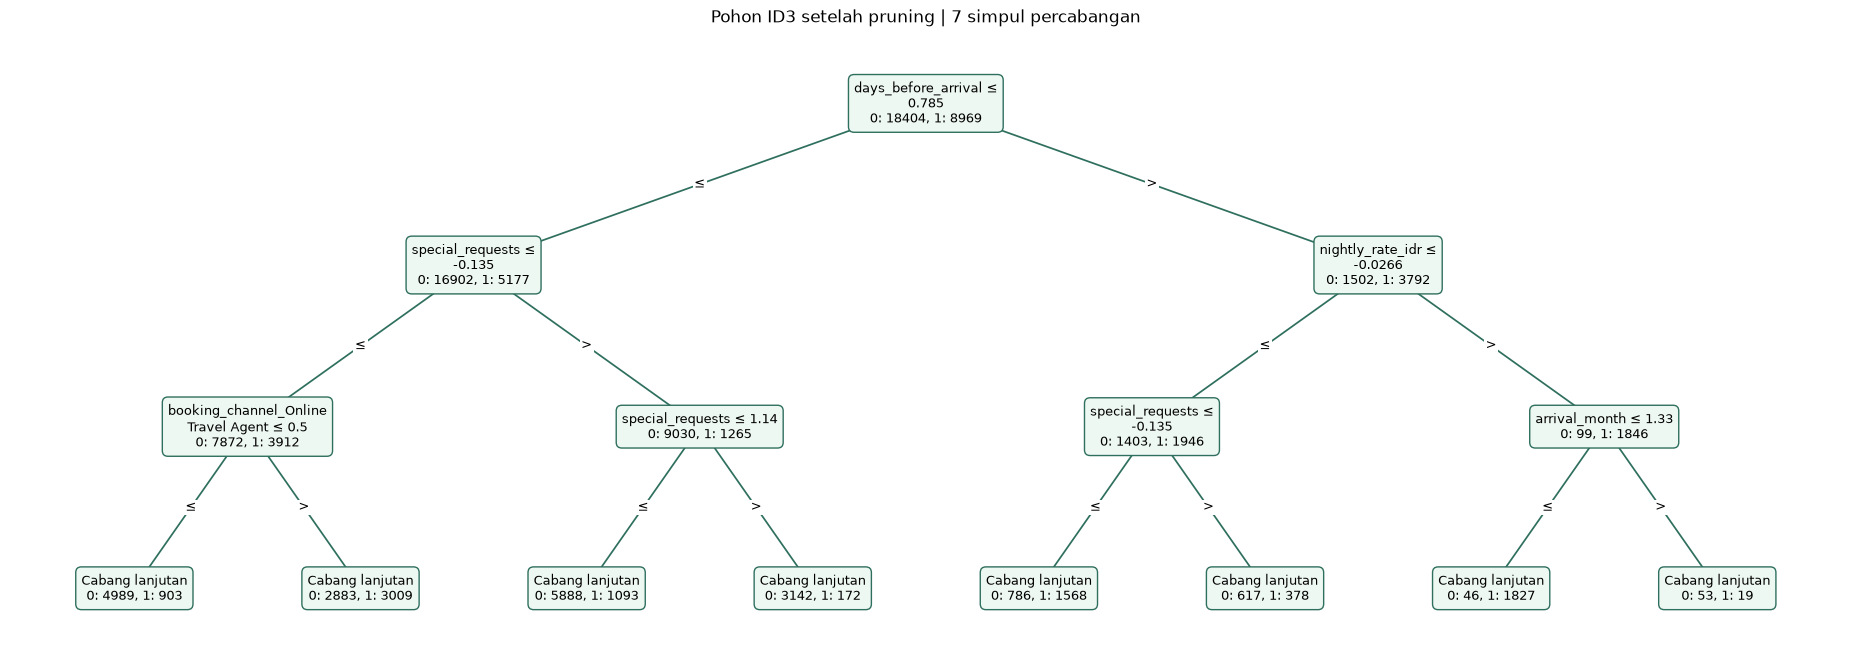

In [11]:
from IPython.display import Video
from analysis.bonus import (
    plot_dtl_tree, plot_naive_bayes_graph, plot_svm_kernels, save_lr_loss_video,
)

output_bonus = root / "output" / "bonus"
output_bonus.mkdir(parents=True, exist_ok=True)

fig_dtl_bonus = plot_dtl_tree(
    model_dtl_muat, preprocessor_dtl_muat.get_feature_names_out(), top_n=7
)
fig_dtl_bonus.savefig(output_bonus / "dtl_tree.png", dpi=160)
plt.show()


**Hasil:** Akar pohon membagi pemesanan berdasarkan jarak pemesanan sebelum kedatangan. Simpul yang masih dapat bercabang di luar batas tampilan diberi label Cabang lanjutan.


## Kontur Log-Loss Logistic Regression

Video menampilkan pelatihan Logistic Regression dengan satu fitur, `days_before_arrival`. Dua parameter yang ditampilkan adalah intersep $\theta_0$ dan koefisien fitur $\theta_1$. Kontur log-loss dihitung dari sampel latih yang sama dengan yang digunakan untuk merekam posisi parameter pada akhir setiap epoch. Pembuatan MP4 menggunakan FFmpeg.


In [12]:
fitur_lr_bonus = X_train_siap[["days_before_arrival"]].sample(
    n=min(1500, len(X_train_siap)), random_state=SEED
)
video_lr = output_bonus / "lr_log_loss.mp4"
model_lr_bonus = save_lr_loss_video(
    fitur_lr_bonus, y_train.loc[fitur_lr_bonus.index], video_lr, random_state=SEED
)
display(Video(filename=str(video_lr), embed=True, width=640))


**Hasil:** Video merekam posisi parameter dari inisialisasi hingga akhir pelatihan. Warna garis kontur menunjukkan tingkat log-loss untuk pasangan parameter pada sampel yang divisualisasikan.


## Batas Keputusan SVM

Tiga model SVM untuk visualisasi dilatih pada sampel yang sama dengan dua fitur terstandardisasi, yaitu jarak waktu pemesanan sebelum kedatangan (`days_before_arrival`) dan harga per malam (`nightly_rate_idr`). Warna titik menunjukkan label aktual dan warna latar menunjukkan kelas prediksi. Garis utuh menunjukkan batas keputusan pada skor 0, garis putus-putus menunjukkan margin pada skor −1 dan +1, dan lingkaran kosong menandai *support vector*.


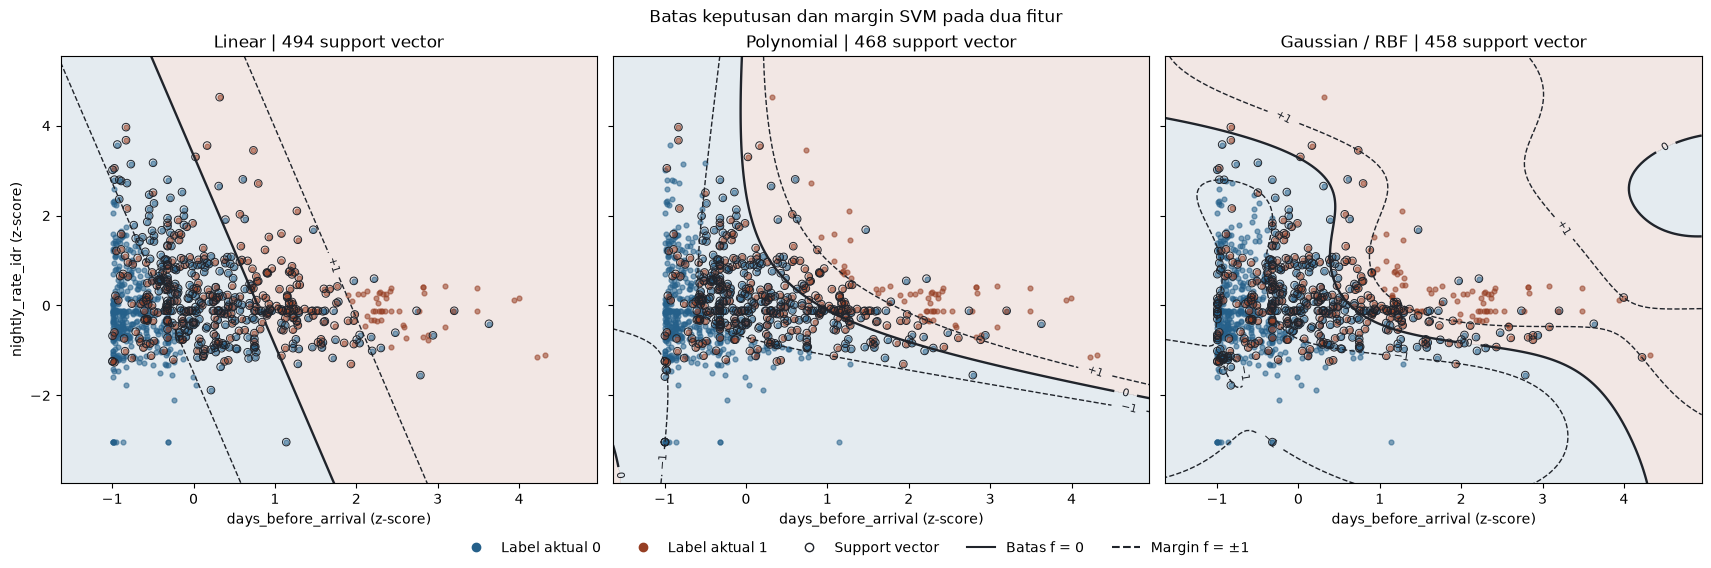

In [13]:
kolom_svm_bonus = ["days_before_arrival", "nightly_rate_idr"]
X_svm_bonus, _, y_svm_bonus, _ = train_test_split(
    X_train_siap[kolom_svm_bonus], y_train, train_size=900, stratify=y_train, random_state=SEED
)
label_svm_bonus = [f"{kolom} (z-score)" for kolom in kolom_svm_bonus]
fig_svm_bonus = plot_svm_kernels(X_svm_bonus, y_svm_bonus, label_svm_bonus)
fig_svm_bonus.savefig(output_bonus / "svm_kernels_2d.png", dpi=160)
plt.show()


**Hasil:** Kernel linear menghasilkan batas lurus, sedangkan kernel polynomial dan Gaussian menghasilkan batas melengkung. Pada ketiga panel, label aktual dari kedua kelas masih muncul di wilayah prediksi yang sama. Kedua fitur ini memberikan gambaran bentuk batas keputusan, sementara model SVM untuk submission menggunakan himpunan fitur lengkap.


## Graf Naive Bayes

Graf menggunakan fitur dari Naive Bayes final. Panah berawal dari variabel kelas dan berakhir pada setiap fitur untuk menggambarkan distribusi fitur yang dikondisikan pada kelas.


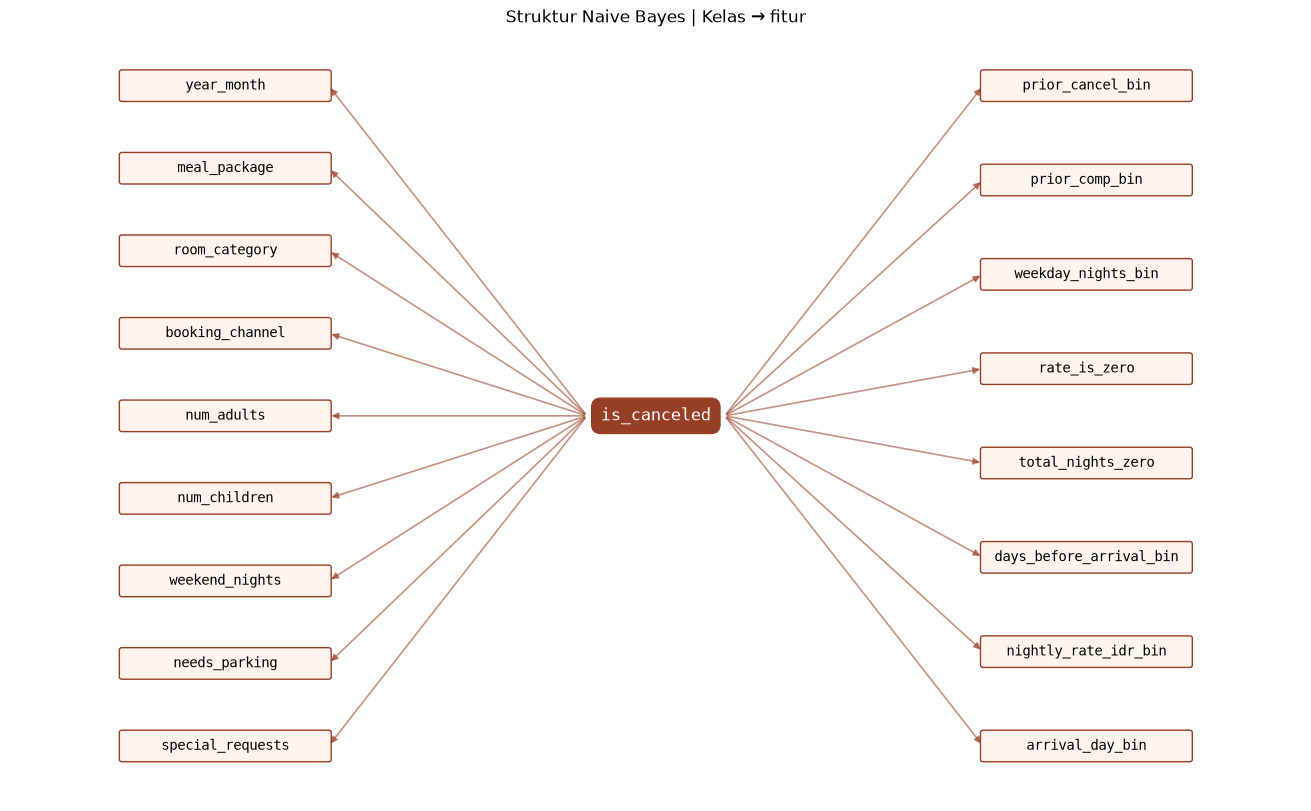

In [14]:
fig_nb_bonus = plot_naive_bayes_graph(model_nb_muat.feature_names_)
fig_nb_bonus.savefig(output_bonus / "naive_bayes_graph.png", dpi=160)
plt.show()


**Hasil:** Graf memperlihatkan 17 fitur yang digunakan pada Naive Bayes final. Struktur panah menggambarkan asumsi bahwa setiap fitur dimodelkan secara terpisah setelah kelas diketahui.


## Cost-Sensitive Classification (`FP = 2 x FN`)

Evaluasi berikut menggunakan biaya false positive dua kali biaya false negative. Untuk model yang menghasilkan probabilitas, ambang teoritisnya adalah 2/3 apabila probabilitas terkalibrasi dan biaya yang diasumsikan berlaku. Ambang SVM dipilih berdasarkan skor pada bagian kalibrasi training. Hasilnya dibandingkan dengan aturan prediksi awal pada data validasi.


In [43]:
COST_FP, COST_FN = 2.0, 1.0
TH_BAYES = COST_FP / (COST_FP + COST_FN)  # 2/3 ~= 0.6667

def eval_cost(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    total_cost = COST_FP * fp + COST_FN * fn
    return {
        "FP (overbook)": int(fp),
        "FN (missed cancel)": int(fn),
        "total_cost": float(total_cost),
        "avg_cost": float(total_cost / len(y_true)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", labels=[0, 1])),
    }

# Untuk SVM (skor margin non-probabilistik), cari threshold biaya minimum pada inner split training
X_sv_it, X_sv_ic, y_sv_it, y_sv_ic = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
p_sv_cal = KNNSVMPreprocessor(
    exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=SEED
)
m_sv_cal = WorkingSetSVM(
    C=4, gamma=0.16, kernel="rbf", tol=0.003, max_iter=200000, cache_mb=512
).fit(p_sv_cal.fit_transform(X_sv_it, y_sv_it), y_sv_it)
sv_ic_scores = m_sv_cal.decision_function(p_sv_cal.transform(X_sv_ic))
th_svm_cost = min(
    np.linspace(-0.5, 1.2, 86),
    key=lambda t: eval_cost(y_sv_ic, (sv_ic_scores >= t).astype(int))["total_cost"],
)

baris_cost = []
for nama, pred_def, pred_cs, info_th in [
    ("KNN", model_knn.predict(X_valid_knn), model_knn.predict(X_valid_knn, threshold=TH_BAYES), f"p >= {TH_BAYES:.3f}"),
    ("DTL", model_dtl.predict(X_valid_dtl), model_dtl.predict(X_valid_dtl, threshold=TH_BAYES), f"p >= {TH_BAYES:.3f}"),
    ("LR", model_lr.predict(X_valid_lr), model_lr.predict(X_valid_lr, threshold=TH_BAYES), f"p >= {TH_BAYES:.3f}"),
    ("Naive Bayes", model_nb.predict(X_valid_nb), model_nb.predict(X_valid_nb, threshold=TH_BAYES), f"p >= {TH_BAYES:.3f}"),
    ("SVM (RBF)", model_svm.predict(X_valid_svm), (model_svm.decision_function(X_valid_svm) >= th_svm_cost).astype(int), f"score >= {th_svm_cost:.2f}"),
]:
    d = eval_cost(y_valid, pred_def)
    c = eval_cost(y_valid, pred_cs)
    baris_cost.append({
        "model": nama, "aturan_cost_sensitive": info_th,
        "FP_awal": d["FP (overbook)"], "FP_baru": c["FP (overbook)"],
        "cost_awal": d["total_cost"], "cost_baru": c["total_cost"],
        "penurunan_cost_%": (d["total_cost"] - c["total_cost"]) / d["total_cost"] * 100,
        "macro_f1_awal": d["macro_f1"], "macro_f1_baru": c["macro_f1"],
    })
display(pd.DataFrame(baris_cost).set_index("model").round(4))

,aturan_cost_sensitive,FP_awal,FP_baru,cost_awal,cost_baru,penurunan_cost_%,macro_f1_awal,macro_f1_baru
model,,,,,,,,
KNN,p >= 0.667,297,94,960.0,812.0,15.4167,0.8612,0.8371
DTL,p >= 0.667,434,230,1246.0,1028.0,17.4960,0.8330,0.8254
LR,p >= 0.667,557,187,1603.0,1293.0,19.3387,0.7852,0.7381
Naive Bayes,p >= 0.667,515,217,1685.0,1371.0,18.6350,0.7524,0.7274
SVM (RBF),score >= 0.46,356,182,1107.0,955.0,13.7308,0.8435,0.8287


**Hasil:** Dengan asumsi biaya yang digunakan, biaya total pada data validasi turun untuk semua model yang ditampilkan, tetapi Macro F1 juga turun. Hasil ini merupakan perbandingan untuk asumsi biaya tersebut, bukan peningkatan Macro F1.
